   id                                           geometry
0   1  MULTIPOLYGON (((-58.02075 -13.84286, -58.00765...
1   2  MULTIPOLYGON (((-58.00734 -13.84936, -58.00642...
2   3  MULTIPOLYGON (((-57.97701 -13.85339, -57.97197...
3   4  MULTIPOLYGON (((-57.96708 -13.85803, -57.94429...
Index(['id', 'geometry'], dtype='object')


<Axes: >

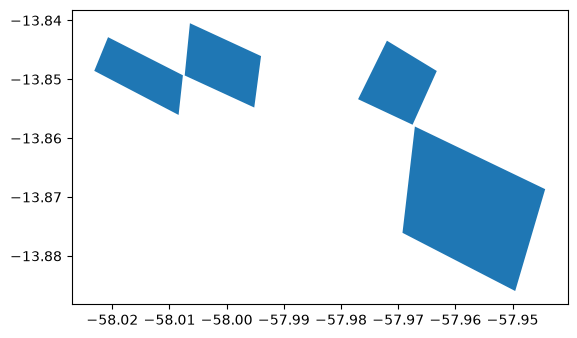

In [1]:
import geopandas as gpd

# Caminho do arquivo GeoJSON
caminho = "../data/polygon_data.geojson"

# Ler o arquivo
gdf = gpd.read_file(caminho)

# Visualizar os dados
print(gdf.head())

# Verificar as colunas
print(gdf.columns)


# Plotar os polígonos
gdf.plot()

In [3]:
import geopandas as gpd
import pystac_client
from odc.stac import load
from shapely.geometry import mapping
import matplotlib.pyplot as plt
import xarray as xr

# 1. Definir o período
data_inicio = "2025-10-08"
data_fim = "2026-03-20"

# 2. Selecionar o polígono ID 1
poligono = gdf.loc[gdf["id"] == 1].to_crs("EPSG:4326")
geometria = poligono.geometry.union_all()

# 3. Conectar ao catálogo STAC da Element 84
catalogo = pystac_client.Client.open(
    "https://earth-search.aws.element84.com/v1"
)

# 4. Buscar cenas Sentinel-2 Collection 1 L2A
busca = catalogo.search(
    collections=["sentinel-2-c1-l2a"],
    intersects=mapping(geometria),
    datetime=f"{data_inicio}/{data_fim}",
    # query={"eo:cloud_cover": {"lt": 20}}
)

itens = list(busca.items())

print(f"Cenas encontradas: {len(itens)}")

if not itens:
    raise ValueError(
        "Nenhuma cena encontrada. Verifique as datas "
        "ou aumente o limite de nuvens."
    )

# 5. Carregar as bandas em um xarray.Dataset
# Usa UTM da região do polígono, com resolução de 10 m.
# Os dados são carregados sob demanda com Dask.
ds = load(
    itens,
    bands=["red", "green", "blue", "nir", "scl"],
    geopolygon=poligono.geometry.union_all(),
    resolution=10,
    chunks={},
    groupby="solar_day",
)

c:\Users\Isabela\Documents\Projetos\venv-agro\Lib\site-packages\pystac\extensions\storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


Cenas encontradas: 44


In [4]:
ds

<xarray.Dataset> Size: 10MB
Dimensions:      (y: 146, x: 168, time: 44)
Coordinates:
  * y            (y) float64 1kB 8.469e+06 8.469e+06 ... 8.468e+06 8.468e+06
  * x            (x) float64 1kB 3.894e+05 3.894e+05 ... 3.911e+05 3.911e+05
  * time         (time) datetime64[ns] 352B 2025-10-10T14:16:29.361000 ... 20...
    spatial_ref  int32 4B 32721
Data variables:
    red          (time, y, x) uint16 2MB dask.array<chunksize=(1, 146, 168), meta=np.ndarray>
    green        (time, y, x) uint16 2MB dask.array<chunksize=(1, 146, 168), meta=np.ndarray>
    blue         (time, y, x) uint16 2MB dask.array<chunksize=(1, 146, 168), meta=np.ndarray>
    nir          (time, y, x) uint16 2MB dask.array<chunksize=(1, 146, 168), meta=np.ndarray>
    scl          (time, y, x) uint8 1MB dask.array<chunksize=(1, 146, 168), meta=np.ndarray>

In [5]:
red = ds["red"].astype("float32") / 10000
nir = ds["nir"].astype("float32") / 10000

denominador = nir + 2.4 * red + 1

ds["evi2"] = xr.where(
    denominador != 0,
    2.5 * (nir - red) / denominador,
    float("nan")
)


In [6]:
ds

<xarray.Dataset> Size: 14MB
Dimensions:      (y: 146, x: 168, time: 44)
Coordinates:
  * y            (y) float64 1kB 8.469e+06 8.469e+06 ... 8.468e+06 8.468e+06
  * x            (x) float64 1kB 3.894e+05 3.894e+05 ... 3.911e+05 3.911e+05
  * time         (time) datetime64[ns] 352B 2025-10-10T14:16:29.361000 ... 20...
    spatial_ref  int32 4B 32721
Data variables:
    red          (time, y, x) uint16 2MB dask.array<chunksize=(1, 146, 168), meta=np.ndarray>
    green        (time, y, x) uint16 2MB dask.array<chunksize=(1, 146, 168), meta=np.ndarray>
    blue         (time, y, x) uint16 2MB dask.array<chunksize=(1, 146, 168), meta=np.ndarray>
    nir          (time, y, x) uint16 2MB dask.array<chunksize=(1, 146, 168), meta=np.ndarray>
    scl          (time, y, x) uint8 1MB dask.array<chunksize=(1, 146, 168), meta=np.ndarray>
    evi2         (time, y, x) float32 4MB dask.array<chunksize=(1, 146, 168), meta=np.ndarray>

In [ ]:
# Salvar o dataset em Zarr
ds.to_zarr(
    "../data/id1_sentinel-2-c1-l2a.zarr",
    mode="w"
)